<a href="https://colab.research.google.com/github/deepak-kumar-da/smart-comment-classifier/blob/main/notebooks/04_classical_ml_baselines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

import os
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,average_precision_score

BASE = "/content/drive/MyDrive/Smart_Comment_Classifier"
PROCESSED = f"{BASE}/datasets/processed"
REPORTS = f"{BASE}/datasets/reports"
MODELS = f"{BASE}/datasets/models"
OUTPUTS = f"{BASE}/datasets/outputs"

for folder in [REPORTS,MODELS,OUTPUTS]:
  os.makedirs(folder,exist_ok=True)

RANDOM_STATE = 42

Mounted at /content/drive


In [ ]:
jigsaw = pd.read_csv(f"{PROCESSED}/jigsaw_toxicity_final.csv")
uci = pd.read_csv(f"{PROCESSED}/uci_spam_final.csv")
youtube_spam = pd.read_csv(f"{PROCESSED}/youtube_spam_final.csv")
youtube_toxicity = pd.read_csv(f"{PROCESSED}/youtube_toxicity_final.csv")

In [ ]:
# Prepare spam labels

def normalize_binary_label(value):
  value = str(value).strip().lower()
  mapping = {
      "1":1,
      "0":0,
      "spam":1,
      "not spam":0,
      "non-spam":0,
      "ham":0
  }

  if value in mapping:
    return mapping[value]
  return np.nan

uci["label"] = uci["label"].apply(normalize_binary_label)
youtube_spam["label"] = youtube_spam["label"].apply(normalize_binary_label)

uci = uci.dropna(subset=["text","label"]).copy()
youtube_spam = youtube_spam.dropna(subset=["text","label"]).copy()

uci["label"] = uci["label"].astype(int)
youtube_spam["label"] = youtube_spam["label"].astype(int)

print("UCI usable records",len(uci))
print("Youtube usable records",len(youtube_spam))

UCI usable records 1741
Youtube usable records 14032


In [ ]:
# train/test split

X_train,X_test,y_train,y_test = train_test_split(
    uci["text"].astype(str),
    uci["label"],
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=uci["label"]
)

print("Training Records:",len(X_train))
print("Testing Records:",len(X_test))

print("\nTraining distribution")
print(y_train.value_counts(normalize=True))

print("\nTesting distribution")
print(y_test.value_counts(normalize=True))

Training Records: 1392
Testing Records: 349

Training distribution
label
0    0.519397
1    0.480603
Name: proportion, dtype: float64

Testing distribution
label
0    0.518625
1    0.481375
Name: proportion, dtype: float64


In [ ]:
# TF-IDF feature extraction

spam_vectorizer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1,2),
    min_df=2,
    max_features=100000,
    sublinear_tf=True
)

X_train_tfidf = spam_vectorizer.fit_transform(X_train)
X_test_tfidf = spam_vectorizer.transform(X_test)

print("Training TF-IDF shape",X_train_tfidf.shape)
print("Testing TF-IDF shape",X_test_tfidf.shape)
print("Vocab Size",len(spam_vectorizer.vocabulary_))

Training TF-IDF shape (1392, 3524)
Testing TF-IDF shape (349, 3524)
Vocab Size 3524


In [ ]:
# training

spam_models = {
    "Naive Bayes":MultinomialNB(alpha=0.5),
    "Logistics Regression":LogisticRegression(
        C=1,
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE
    ),
    "Linear SVM":LinearSVC(
        C=1,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )
}

spam_results = []
trained_spam_models = {}

for name,model in spam_models.items():
  print(f"Training {name}")
  model.fit(X_train_tfidf,y_train)
  predictions = model.predict(X_test_tfidf)
  result = {
      "model":name,
      "accuracy":accuracy_score(y_test,predictions),
      "precision":precision_score(y_test,predictions,zero_division=0),
      "f1":f1_score(y_test,predictions,zero_division=0)
  }

  spam_results.append(result)
  trained_spam_models[name] = model

  print(classification_report(
      y_test,
      predictions,
      target_names=["Not Spam","Spam"],
      zero_division=0
  ))

spam_results_df = pd.DataFrame(spam_results)
display(spam_results_df.sort_values("f1",ascending=False))

Training Naive Bayes
              precision    recall  f1-score   support

    Not Spam       0.92      0.95      0.93       181
        Spam       0.94      0.91      0.93       168

    accuracy                           0.93       349
   macro avg       0.93      0.93      0.93       349
weighted avg       0.93      0.93      0.93       349

Training Logistics Regression
              precision    recall  f1-score   support

    Not Spam       0.93      0.99      0.96       181
        Spam       0.99      0.92      0.95       168

    accuracy                           0.95       349
   macro avg       0.96      0.95      0.95       349
weighted avg       0.96      0.95      0.95       349

Training Linear SVM
              precision    recall  f1-score   support

    Not Spam       0.95      0.98      0.96       181
        Spam       0.98      0.95      0.96       168

    accuracy                           0.96       349
   macro avg       0.96      0.96      0.96       349
wei

,model,accuracy,precision,f1
2,Linear SVM,0.962751,0.975460,0.960725
1,Logistics Regression,0.954155,0.987179,0.950617
0,Naive Bayes,0.931232,0.944444,0.927273


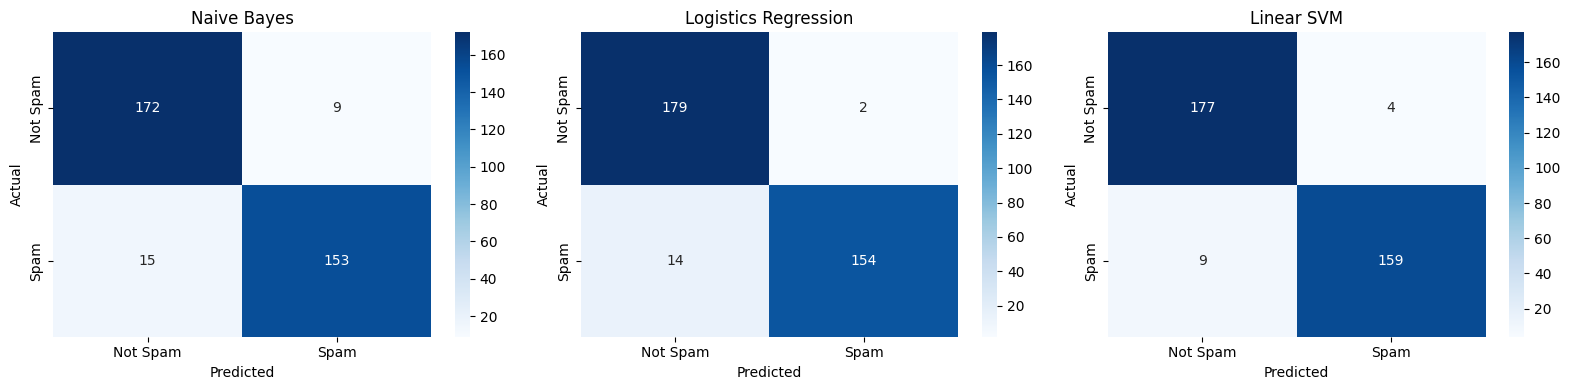

In [ ]:
# confusion matrix

fig,axes = plt.subplots(1,3,figsize=(16,4))

for ax,(name,model) in zip(axes,trained_spam_models.items()):
  predictions = model.predict(X_test_tfidf)
  cm = confusion_matrix(y_test,predictions)
  sns.heatmap(
      cm,
      annot=True,
      fmt="d",
      cmap="Blues",
      xticklabels=["Not Spam","Spam"],
      yticklabels=["Not Spam","Spam"],
      ax=ax
  )

  ax.set_title(name)
  ax.set_xlabel("Predicted")
  ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/spam_confusion_matrices.png",dpi=150,bbox_inches="tight")
plt.show()

In [ ]:
# youtube 45k

X_external_spam = spam_vectorizer.transform(youtube_spam["text"].astype(str))
y_external_spam = youtube_spam["label"]

external_spam_results = []

for name,model in trained_spam_models.items():
  predictions = model.predict(X_external_spam)
  result = {
      "model":name,
      "external_accuracy":accuracy_score(y_external_spam,predictions),
      "external_precision":precision_score(y_external_spam,predictions,zero_division=0),
      "external_recall":recall_score(y_external_spam,predictions,zero_division=0),
      "external_f1":f1_score(y_external_spam,predictions,zero_division=0)
  }

  external_spam_results.append(result)

external_spam_df = pd.DataFrame(external_spam_results)
display(external_spam_df.sort_values("external_f1",ascending=False))

,model,external_accuracy,external_precision,external_recall,external_f1
1,Logistics Regression,0.841790,0.089397,0.877551,0.162264
2,Linear SVM,0.825470,0.080350,0.861224,0.146987
0,Naive Bayes,0.705031,0.050346,0.889796,0.095301


In [ ]:
# Prepare toxicity data

toxicity_labels = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

jigsaw = jigsaw.dropna(subset=["text"] + toxicity_labels).copy()

X = jigsaw["text"].astype(str)
Y = jigsaw[toxicity_labels].astype(int)

print("Records",len(X))
print("Number of labels",len(toxicity_labels))
print("\nPositive label counts")
print(Y.sum())

Records 159272
Number of labels 6

Positive label counts
toxic            15215
severe_toxic      1585
obscene           8407
threat             469
insult            7835
identity_hate     1394
dtype: int64


In [ ]:
!pip -q install iterative-stratification

In [ ]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=RANDOM_STATE
)

train_idx,test_idx = next(splitter.split(X,Y))

X_train_tox = X.iloc[train_idx]
X_test_tox = X.iloc[test_idx]

Y_train_tox = Y.iloc[train_idx]
Y_test_tox = Y.iloc[test_idx]

print("Training Records",len(X_train_tox))
print("Testing Records",len(X_test_tox))

print("\nTraining distribution")
print(Y_train_tox.sum())

print("\nTesting distribution")
print(Y_test_tox.sum())

Training Records 127417
Testing Records 31855

Training distribution
toxic            12172
severe_toxic      1268
obscene           6726
threat             375
insult            6268
identity_hate     1115
dtype: int64

Testing distribution
toxic            3043
severe_toxic      317
obscene          1681
threat             94
insult           1567
identity_hate     279
dtype: int64


In [ ]:
# toxicity TF-IDF

toxicity_vectorizer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1,2),
    min_df=2,
    max_features=200000,
    sublinear_tf=True
)

X_train_tox_tfidf = toxicity_vectorizer.fit_transform(X_train_tox)
X_test_tox_tfidf = toxicity_vectorizer.transform(X_test_tox)

print("Training TF-IDF shape",X_train_tox_tfidf.shape)
print("Testing TF-IDF shape",X_test_tox_tfidf.shape)
print("Vocab Size",len(toxicity_vectorizer.vocabulary_))

Training TF-IDF shape (127417, 200000)
Testing TF-IDF shape (31855, 200000)
Vocab Size 200000


In [ ]:
# Train toxicity classifier

toxicity_algorithms = {
    "Naive Bayes": lambda: MultinomialNB(alpha=0.5),

    "Logistics Regression": lambda: LogisticRegression(
        C=1,
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE
    ),

    "Linear SVM": lambda: LinearSVC(
        C=1,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )
}

target_labels = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

toxicity_models = {}
toxicity_results = []

for algorithm_name, model_factory in toxicity_algorithms.items():
  toxicity_models[algorithm_name] = {}

  print(f"\n{'='*55}")
  print("Algorithm", algorithm_name)
  print(f"{'='*55}")

  for label in target_labels:
    model = model_factory()
    model.fit(X_train_tox_tfidf, Y_train_tox[label])
    predictions = model.predict(X_test_tox_tfidf)
    result = {
        "algorithm": algorithm_name,
        "label": label,
        "precision": precision_score(Y_test_tox[label], predictions, zero_division=0),
        "recall": recall_score(Y_test_tox[label], predictions, zero_division=0),
        "f1": f1_score(Y_test_tox[label], predictions, zero_division=0),
        "average_precision": average_precision_score(Y_test_tox[label], model.decision_function(X_test_tox_tfidf)
        if hasattr(model, "decision_function") else model.predict_proba(X_test_tox_tfidf)[:,1])
    }

    toxicity_results.append(result)
    toxicity_models[algorithm_name][label] = model

    print(
        f"{label:<15} "
        f"F1={result['f1']:.3f} | "
        f"Precision={result['precision']:.3f} | "
        f"Recall={result['recall']:.3f}"
    )

toxicity_results_df = pd.DataFrame(toxicity_results)
display(toxicity_results_df.sort_values(
    ["label", "f1"],
    ascending=[True, False]
))


Algorithm Naive Bayes
toxic           F1=0.580 | Precision=0.961 | Recall=0.415
severe_toxic    F1=0.043 | Precision=0.875 | Recall=0.022
obscene         F1=0.506 | Precision=0.928 | Recall=0.347
threat          F1=0.000 | Precision=0.000 | Recall=0.000
insult          F1=0.417 | Precision=0.869 | Recall=0.274
identity_hate   F1=0.000 | Precision=0.000 | Recall=0.000

Algorithm Logistics Regression
toxic           F1=0.736 | Precision=0.653 | Recall=0.843
severe_toxic    F1=0.453 | Precision=0.309 | Recall=0.845
obscene         F1=0.778 | Precision=0.695 | Recall=0.885
threat          F1=0.325 | Precision=0.208 | Recall=0.734
insult          F1=0.689 | Precision=0.575 | Recall=0.860
identity_hate   F1=0.384 | Precision=0.265 | Recall=0.699

Algorithm Linear SVM
toxic           F1=0.781 | Precision=0.775 | Recall=0.786
severe_toxic    F1=0.481 | Precision=0.411 | Recall=0.580
obscene         F1=0.803 | Precision=0.792 | Recall=0.814


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


threat          F1=0.420 | Precision=0.500 | Recall=0.362
insult          F1=0.717 | Precision=0.685 | Recall=0.752
identity_hate   F1=0.433 | Precision=0.451 | Recall=0.416


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,algorithm,label,precision,recall,f1,average_precision
17,Linear SVM,identity_hate,0.451362,0.415771,0.432836,0.394821
11,Logistics Regression,identity_hate,0.264586,0.698925,0.383858,0.421130
5,Naive Bayes,identity_hate,0.000000,0.000000,0.000000,0.145991
16,Linear SVM,insult,0.685067,0.752393,0.717153,0.762318
10,Logistics Regression,insult,0.574659,0.859604,0.688826,0.780247
4,Naive Bayes,insult,0.868687,0.274410,0.417071,0.621359
14,Linear SVM,obscene,0.791667,0.813801,0.802581,0.874386
8,Logistics Regression,obscene,0.694860,0.884593,0.778330,0.876975
2,Naive Bayes,obscene,0.928458,0.347412,0.505628,0.700235
13,Linear SVM,severe_toxic,0.410714,0.580442,0.481046,0.422195


,algorithm,precision,recall,f1,average_precision
0,Linear SVM,0.602291,0.618417,0.605665,0.618555
1,Logistics Regression,0.450756,0.810918,0.560733,0.628798
2,Naive Bayes,0.605560,0.176547,0.257643,0.433947


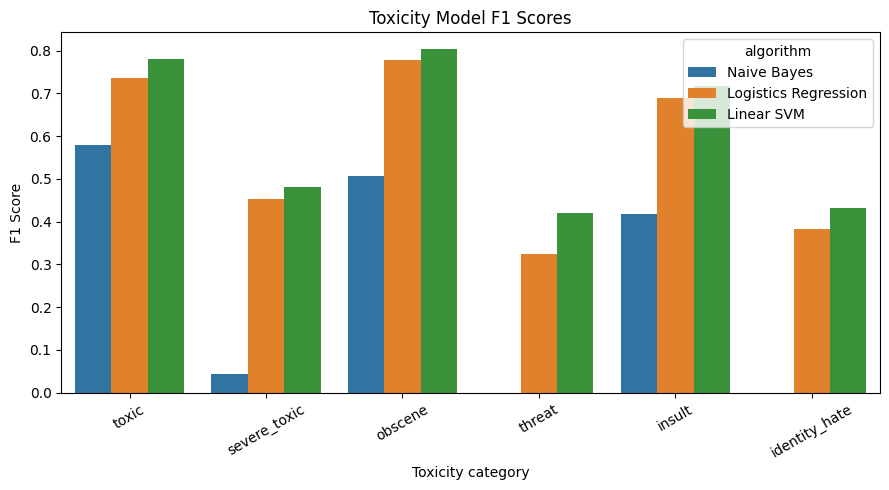

In [ ]:
# comparision

toxicity_comparison = (
    toxicity_results_df
    .groupby("algorithm")
    .agg({
        "precision": "mean",
        "recall": "mean",
        "f1": "mean",
        "average_precision": "mean"
    })
    .reset_index()
)

display(toxicity_comparison.sort_values("f1", ascending=False))

plt.figure(figsize=(9,5))

sns.barplot(
    data = toxicity_results_df,
    x="label",
    y="f1",
    hue="algorithm"
)

plt.title("Toxicity Model F1 Scores")
plt.xlabel("Toxicity category")
plt.ylabel("F1 Score")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(f"{OUTPUTS}/toxicity_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# evaluation

def normalize_toxicity_label(value):
  value = str(value).strip().lower()
  mapping = {
      "toxic": 1,
      "non toxic":0,
      "non-toxic":0,
      "nontoxic":0,
      "1":1,
      "0":0
  }

  return mapping.get(value,np.nan)

yt_tox = youtube_toxicity.copy()

yt_tox["binary_label"] = yt_tox["label"].apply(normalize_toxicity_label)
yt_tox = yt_tox.dropna(subset=["text","binary_label"])

X_yt_tox = toxicity_vectorizer.transform(yt_tox["text"].astype(str))
y_yt_tox = yt_tox["binary_label"].astype(int)

external_toxicity_results = []

for algorithm_name, models_dict in toxicity_models.items():
  model = models_dict["toxic"]
  predictions = model.predict(X_yt_tox)
  external_toxicity_results.append({
      "algorithm": algorithm_name,
      "accuracy":accuracy_score(y_yt_tox,predictions),
      "precision":precision_score(y_yt_tox,predictions,zero_division=0),
      "recall":recall_score(y_yt_tox,predictions,zero_division=0),
      "f1":f1_score(y_yt_tox,predictions,zero_division=0)
  })

external_toxicity_df = pd.DataFrame(external_toxicity_results)
display(external_toxicity_df)

,algorithm,accuracy,precision,recall,f1
0,Naive Bayes,0.946416,0.740000,0.047680,0.089588
1,Logistics Regression,0.923828,0.380016,0.597938,0.464697
2,Linear SVM,0.948767,0.542348,0.470361,0.503796


In [ ]:
# save trained models

import joblib

#spam
joblib.dump(spam_vectorizer,f"{MODELS}/spam_tfidf_vectorizer.pkl")
joblib.dump(trained_spam_models,f"{MODELS}/spam_classical_models.pkl")

#toxicity
joblib.dump(toxicity_vectorizer,f"{MODELS}/toxicity_tfidf_vectorizer.pkl")
joblib.dump(toxicity_models,f"{MODELS}/toxicity_classical_models.pkl")

['/content/drive/MyDrive/Smart_Comment_Classifier/datasets/models/toxicity_classical_models.pkl']

In [ ]:
# evaluation report

spam_results_df.to_csv(f"{REPORTS}/spam_internal_evaluation.csv",index=False)

external_spam_df.to_csv(f"{REPORTS}/spam_external_weak_label_evaluation.csv",index=False)

toxicity_results_df.to_csv(f"{REPORTS}/toxicity_internal_evaluation.csv",index=False)

toxicity_comparison.to_csv(f"{REPORTS}/toxicity_algorithm_comparison.csv",index=False)

external_toxicity_df.to_csv(f"{REPORTS}/toxicity_external_weak_label_evaluation.csv",index=False)